In [1]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Convert_Bispectrum/')

import os
import h5py
import numpy as np
import pandas as pd
import Visual_Helpers as VH
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d as inter
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

cmap = plt.get_cmap("tab10")

In [15]:
pos_root = '../../Data/Gala_z8_Positions/'
phases = 25
L = 2000
num_splits = 1
len_split = L / num_splits

counts = []
for ph in np.arange(phases):
    pos_file = pos_root + 'Gala_ph0' + '{:02d}'.format(ph) + '.h5'
    with h5py.File(pos_file, 'r') as f_:
        pos = f_['dataset'][:].T

    idx = (pos * (num_splits / L)).astype(np.int64)      # cell index per axis
    np.clip(idx, 0, num_splits - 1, out=idx)             # guard pos == L exactly
    flat = (idx[:, 0] * num_splits + idx[:, 1]) * num_splits + idx[:, 2]
    counts.append(np.bincount(flat, minlength=num_splits**3))

counts = np.concatenate(counts)

In [19]:
std = np.std(counts)/4

def density(count):
    return np.sum([np.exp(-(count-counts[i])**2/(2*std**2))/np.sqrt(2*std**2*np.pi) for i in np.arange(phases)])/25

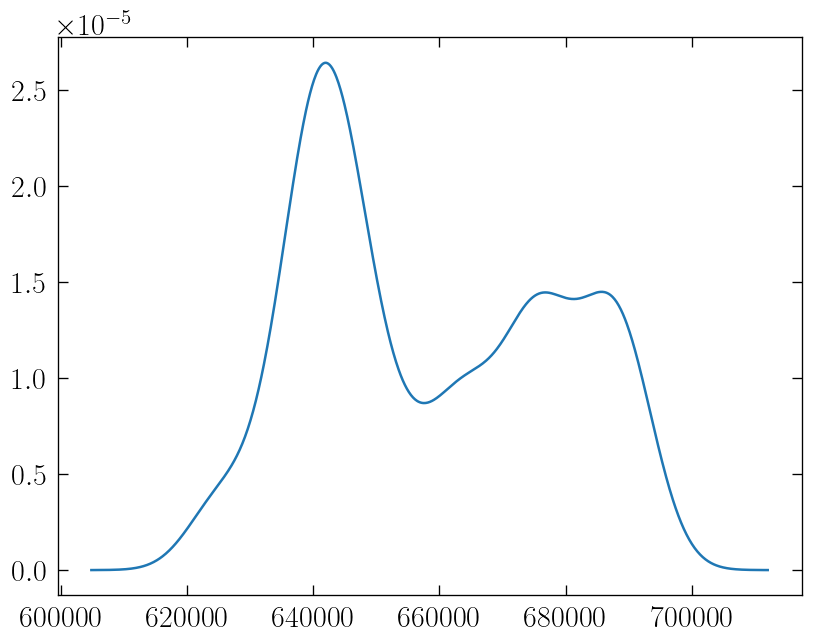

In [20]:
x = np.linspace(np.min(counts)-np.std(counts), np.max(counts)+np.std(counts), 1000)
y = []
for ind_x in x:
    y.append(density(ind_x))
y = np.array(y)

plt.figure(dpi = 120)
plt.plot(x,y)
plt.show()

In [11]:
num_samples = 100

pois = np.random.poisson(lam=np.mean(counts), size=len(counts)*num_samples)

In [12]:
extra_noise = np.std(counts) / np.std(pois)
super_pois = extra_noise * (pois - np.mean(counts)) + np.mean(counts)
super_pois = np.reshape(super_pois, (num_samples, len(counts)))

In [13]:
bins = np.linspace(np.min(counts), np.max(counts), 21)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

lo_per = 16
hi_per = 84

c = np.zeros((num_samples, len(bins)-1))

for i in np.arange(len(c)):
    c[i], _ = np.histogram(super_pois[i], bins=bins, density=True)

mean = np.percentile(c, 50, axis=0)
lo = np.percentile(c, lo_per, axis=0)
hi = np.percentile(c, hi_per, axis=0)

yerr = np.vstack([mean - lo, hi - mean])

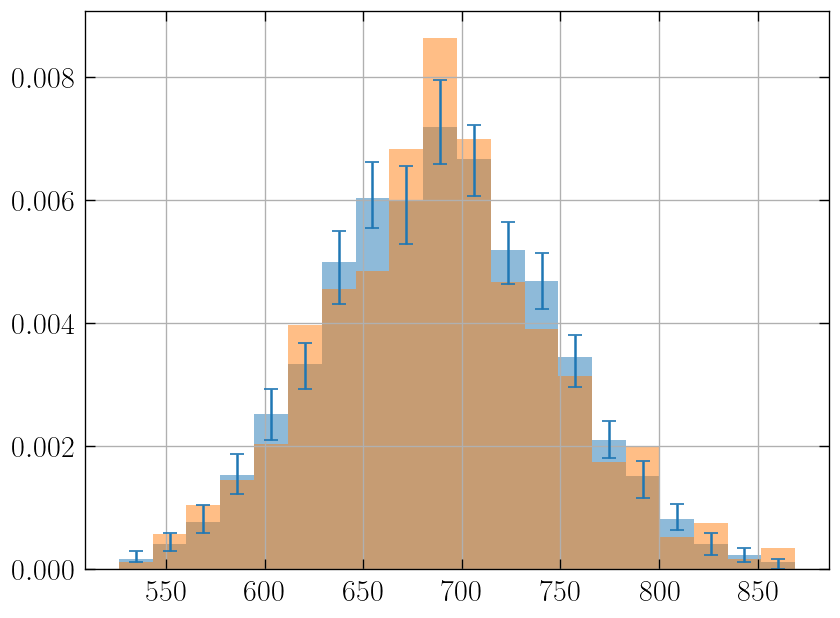

In [14]:
plt.figure(dpi = 120)
plt.hist(bin_centers, weights=mean, bins=bins, alpha=0.5, label='Expected Super Poisson', color=cmap(0))
plt.errorbar(bin_centers, mean, yerr=yerr, fmt='none', color=cmap(0), capsize=4)
plt.hist(counts, bins=bins, density=True, alpha=0.5, label='Data', color=cmap(1))
plt.grid()
# plt.legend()
plt.show()